# E6 — Contact taps and holds (Inverse3)

`e6_taps.py`. Per run, the contact metrics averaged over its taps, the stability indicators (bounces,
settling, HF force RMS above 8 Hz) and the energy balance (E < 0: the system generated energy).

In [11]:
# Runs to analyse: run directories, session files (exp/<exp>/sessions/*.txt, written by the script) or a
# folder of runs (a folder also holds retried and superseded runs). Default: the latest session file,
# which lists every condition once.
from common import latest_session

RUNS = [latest_session("e6")]
RECOMPUTE = False  # True: recompute the metrics from the data instead of reading analysis/metrics.json

In [12]:
import os

os.environ.setdefault("JAX_PLATFORMS", "cpu")  # before anything imports JAX: the GPU stays free for fr3_teleop's IK
import sys
from pathlib import Path

HERE = Path.cwd()  # experiments/rim-delays/exp
sys.path[:0] = [str(HERE), str(HERE.parent)]
import matplotlib.pyplot as plt  # noqa: I001
import numpy as np
import pandas as pd

import exp_metrics
import plots as P
from common import collect, load_table

%matplotlib inline
%load_ext autoreload
%autoreload 2
pd.set_option("display.precision", 3)

runs = collect(RUNS)
df = load_table(runs, exp_metrics.e6 if RECOMPUTE else None)
print(f"{len(df)} runs")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
16 runs


In [13]:
cols = [
    "run",
    "method",
    "rtt",
    "contacts",
    "onset_latency_ms_mean",
    "penetration_at_onset_mm_mean",
    "overshoot_mean",
    "settling_ms_mean",
    "bounces_mean",
    "hf_rms_N_mean",
    "robot_peak_table_N_mean",
    "E_end_J",
    "E_min_J",
]
df[cols].sort_values(["method", "rtt"])

,run,method,rtt,contacts,onset_latency_ms_mean,penetration_at_onset_mm_mean,overshoot_mean,settling_ms_mean,bounces_mean,hf_rms_N_mean,robot_peak_table_N_mean,E_end_J,E_min_J
8,20261027_184704_e6_proxy-fixed-mass_rtt0_guided,proxy-fixed-mass,0,6,23.500,2.438,1.355,300.167,0.0,0.146,10.297,-2.081,-2.082e+00
10,20261027_184940_e6_proxy-fixed-mass_rtt850_guided,proxy-fixed-mass,850,6,26.332,2.787,1.168,152.503,0.0,0.175,10.028,-1.605,-1.605e+00
11,20261027_185130_e6_proxy-fixed-mass_rtt2600_gu...,proxy-fixed-mass,2600,6,27.502,3.017,1.222,118.995,0.0,0.143,10.365,-1.664,-1.664e+00
9,20261027_184825_e6_proxy-fixed-mass_rtt5g_guided,proxy-fixed-mass,5g,6,25.673,2.916,1.318,318.998,0.0,0.163,10.971,-1.510,-1.510e+00
4,20261027_184150_e6_proxy-god-object_rtt0_guided,proxy-god-object,0,6,0.000,0.046,1.660,503.001,0.0,0.129,9.239,-2.793,-2.793e+00
6,20261027_184430_e6_proxy-god-object_rtt850_guided,proxy-god-object,850,6,0.000,0.032,1.327,402.833,0.0,0.151,9.448,-2.092,-2.092e+00
7,20261027_184551_e6_proxy-god-object_rtt2600_gu...,proxy-god-object,2600,6,0.000,0.072,1.322,539.833,0.0,0.145,10.366,-2.064,-2.064e+00
5,20261027_184313_e6_proxy-god-object_rtt5g_guided,proxy-god-object,5g,6,0.000,0.055,1.253,314.499,0.0,0.120,8.737,-2.172,-2.210e+00
12,20261027_185300_e6_proxy-rim_rtt0_guided,proxy-rim,0,6,23.832,2.578,1.180,172.837,0.0,0.146,9.905,-1.632,-1.632e+00
14,20261027_185601_e6_proxy-rim_rtt850_guided,proxy-rim,850,6,30.171,3.542,1.344,652.996,0.0,0.136,11.720,-1.665,-1.665e+00


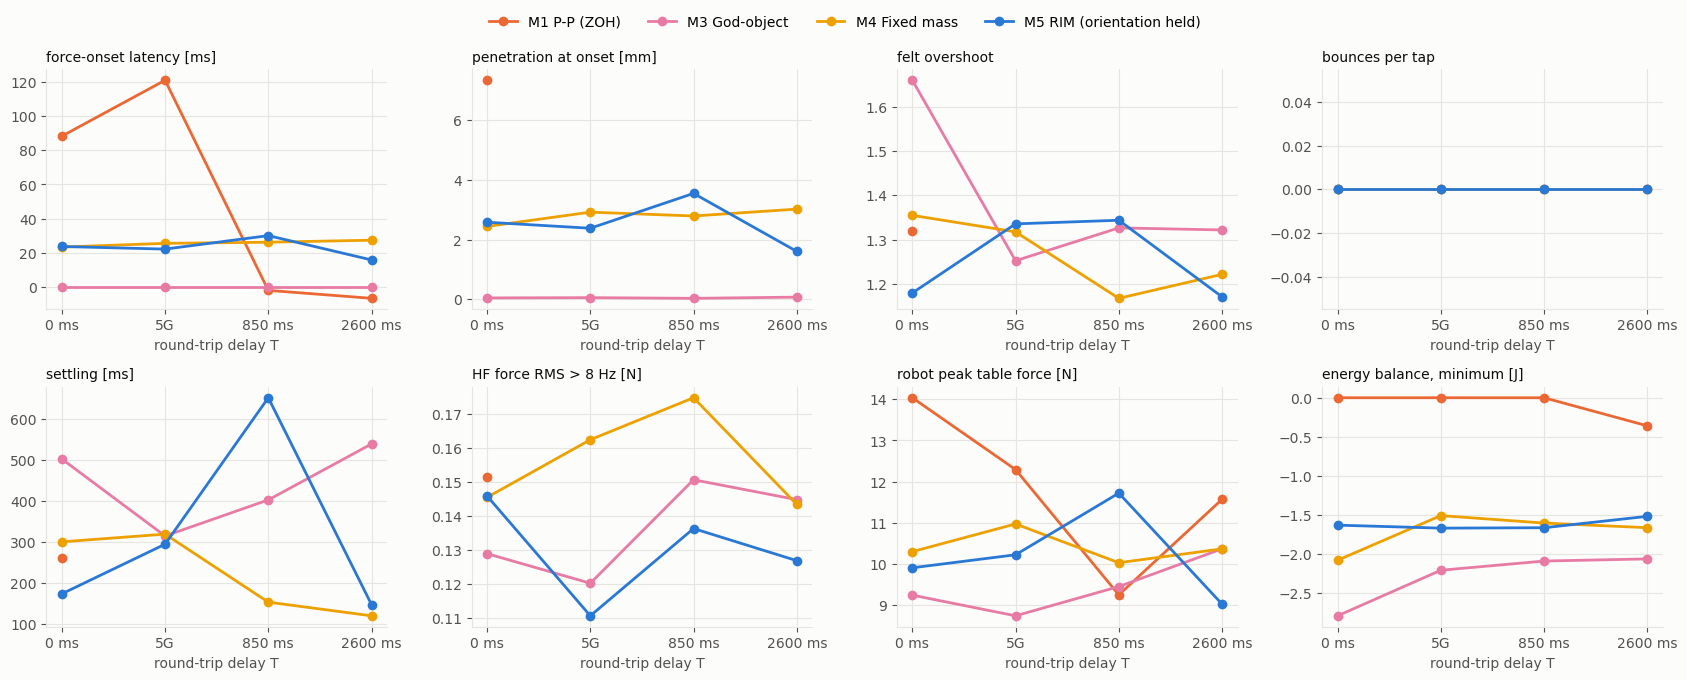

In [14]:
metrics = [
    ("onset_latency_ms_mean", "force-onset latency [ms]"),
    ("penetration_at_onset_mm_mean", "penetration at onset [mm]"),
    ("overshoot_mean", "felt overshoot"),
    ("bounces_mean", "bounces per tap"),
    ("settling_ms_mean", "settling [ms]"),
    ("hf_rms_N_mean", "HF force RMS > 8 Hz [N]"),
    ("robot_peak_table_N_mean", "robot peak table force [N]"),
    ("E_min_J", "energy balance, minimum [J]"),
]
fig, axes = plt.subplots(2, 4, figsize=(17, 6.5))
for ax, (y, title) in zip(axes.ravel(), metrics):
    P.by_delay(ax, df, y, label_methods=(ax is axes[0, 0]))
    ax.set_title(title, loc="left", fontsize=10)
fig.legend(loc="upper center", ncol=4, bbox_to_anchor=(0.5, 1.05))
fig.tight_layout()